# Passenger-centric punctuality: corrected case-study reanalysis

Canonical notebook. It regenerates every corrected table and figure from the tested library code.

In [1]:
from pathlib import Path
import sys
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().resolve()
while not (ROOT / 'src').is_dir() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUTPUT = ROOT / 'output'
pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.2f}')

In [2]:
from scripts.run_case_study_analysis import run

legacy = ROOT / 'tmp' / 'legacy_derived' / 'df_onboard_actual.csv'
run(OUTPUT, legacy if legacy.exists() else None)
display(Markdown((OUTPUT / 'analysis_report.md').read_text(encoding='utf-8')))

# Corrected case-study analysis

## Main findings

- The weekday terminal-service cancellation rate is **9.8%**.
- At the 3-minute threshold, morning OTP is **88.8%** while passenger PP2 is **83.2%**. Afternoon scores are **87.2%** and **83.3%**, respectively.
- Keeping planned passengers exposed to cancellations in the denominator reduces PP2 to **72.1%** in the morning and **75.7%** in the afternoon.
- The original all-days/legacy-bin calculation gives morning PP2 **88.4%**; selecting weekdays and corrected arrival-time bins gives **83.7%**.
- Passenger-weighted median journey time is **17 min** in the morning, not the unweighted train-OD median of 28 min reported by the legacy notebook.
- Corrected mean station EW is **10.6 min** in the morning and **11.1 min** in the afternoon; the legacy OD-expanded calculation was 13.0 and 12.7 min.
- Alighting-passenger weighting increases the measured delay in **80 of 81 station-period cells**. At Cst in the morning peak, the unweighted station-arrival mean is **1.60 min**, compared with **2.07 min** after weighting 211,849 alighting passengers.

## Interpretation safeguards

- PP2 is calculated for observed completed journeys. PP2-C is a conservative cancellation-sensitive extension: planned passengers on a cancelled or unobserved completion are counted as not on time.
- PP2-C is not an individual re-routing model. Eventual arrival after a cancellation needs linked AFC journeys or explicit route-choice assumptions.
- EJT and PP2 share delay information, so their strong negative correlation is partly structural. OD rankings should also consider passenger volume and affected-passenger burden.
- Confidence intervals resample workdays, reflecting day-to-day operational variation rather than treating every train or synthetic passenger estimate as independent.

## Highest affected-passenger OD-period cells

| period         | origin   | destination   |   planned_passengers |   PP2_C |   EJT_minutes |   affected_planned_passengers |   passenger_delay_minutes |
|:---------------|:---------|:--------------|---------------------:|--------:|--------------:|------------------------------:|--------------------------:|
| Afternoon peak | Sst      | Cst           |              34078.7 | 61.5931 |     0.0267211 |                      13088.6  |                   71804.7 |
| Afternoon peak | Cst      | Sst           |              38887.8 | 66.7703 |     0.545607  |                      12922.3  |                   74220.9 |
| Morning peak   | Äs       | Cst           |              27157.1 | 60.7908 |     1.26098   |                      10648.1  |                   54571.9 |
| Afternoon peak | Cst      | Äs            |              28730.6 | 66.3405 |     0.823642  |                       9670.58 |                   60209.8 |
| Morning peak   | Sst      | Cst           |              21643.5 | 60.7941 |     0.114497  |                       8485.53 |                   46605.9 |
| Afternoon peak | Cst      | Åbe           |              21271.2 | 60.9806 |     1.04393   |                       8299.88 |                   51418.8 |
| Afternoon peak | Äs       | Cst           |              19081.2 | 62.184  |     1.3183    |                       7215.74 |                   36715.4 |
| Morning peak   | Åbe      | Cst           |              16866.7 | 60.4167 |     0.718828  |                       6676.41 |                   34812.7 |
| Afternoon peak | Cst      | Ke            |              28950.1 | 77.2455 |     0.080186  |                       6587.45 |                   52293.7 |
| Morning peak   | Cst      | Sst           |              13903   | 53.9175 |     0.410059  |                       6406.84 |                   35222.3 |

## Promising extensions

- Link individual AFC journeys, or simulate explicit passenger re-routing, so cancellation delay measures eventual arrival rather than treating every cancelled journey as a failure.
- Repeat the analysis across lines, seasons, and years with a hierarchical day/line model; one five-week corridor extract cannot establish generality.
- Use multiple imputation or scenario bounds for missing arrival/departure timestamps, especially at Ts and Ngd where the imputed share is unusually high.
- Add crowding or capacity data and test whether passenger exposure predicts delay after controlling for direction, time of day, stopping pattern, and service length.
- Stabilise low-volume OD rankings with empirical-Bayes shrinkage and publish both rate-based and affected-passenger priority lists.


### 01 Data Quality

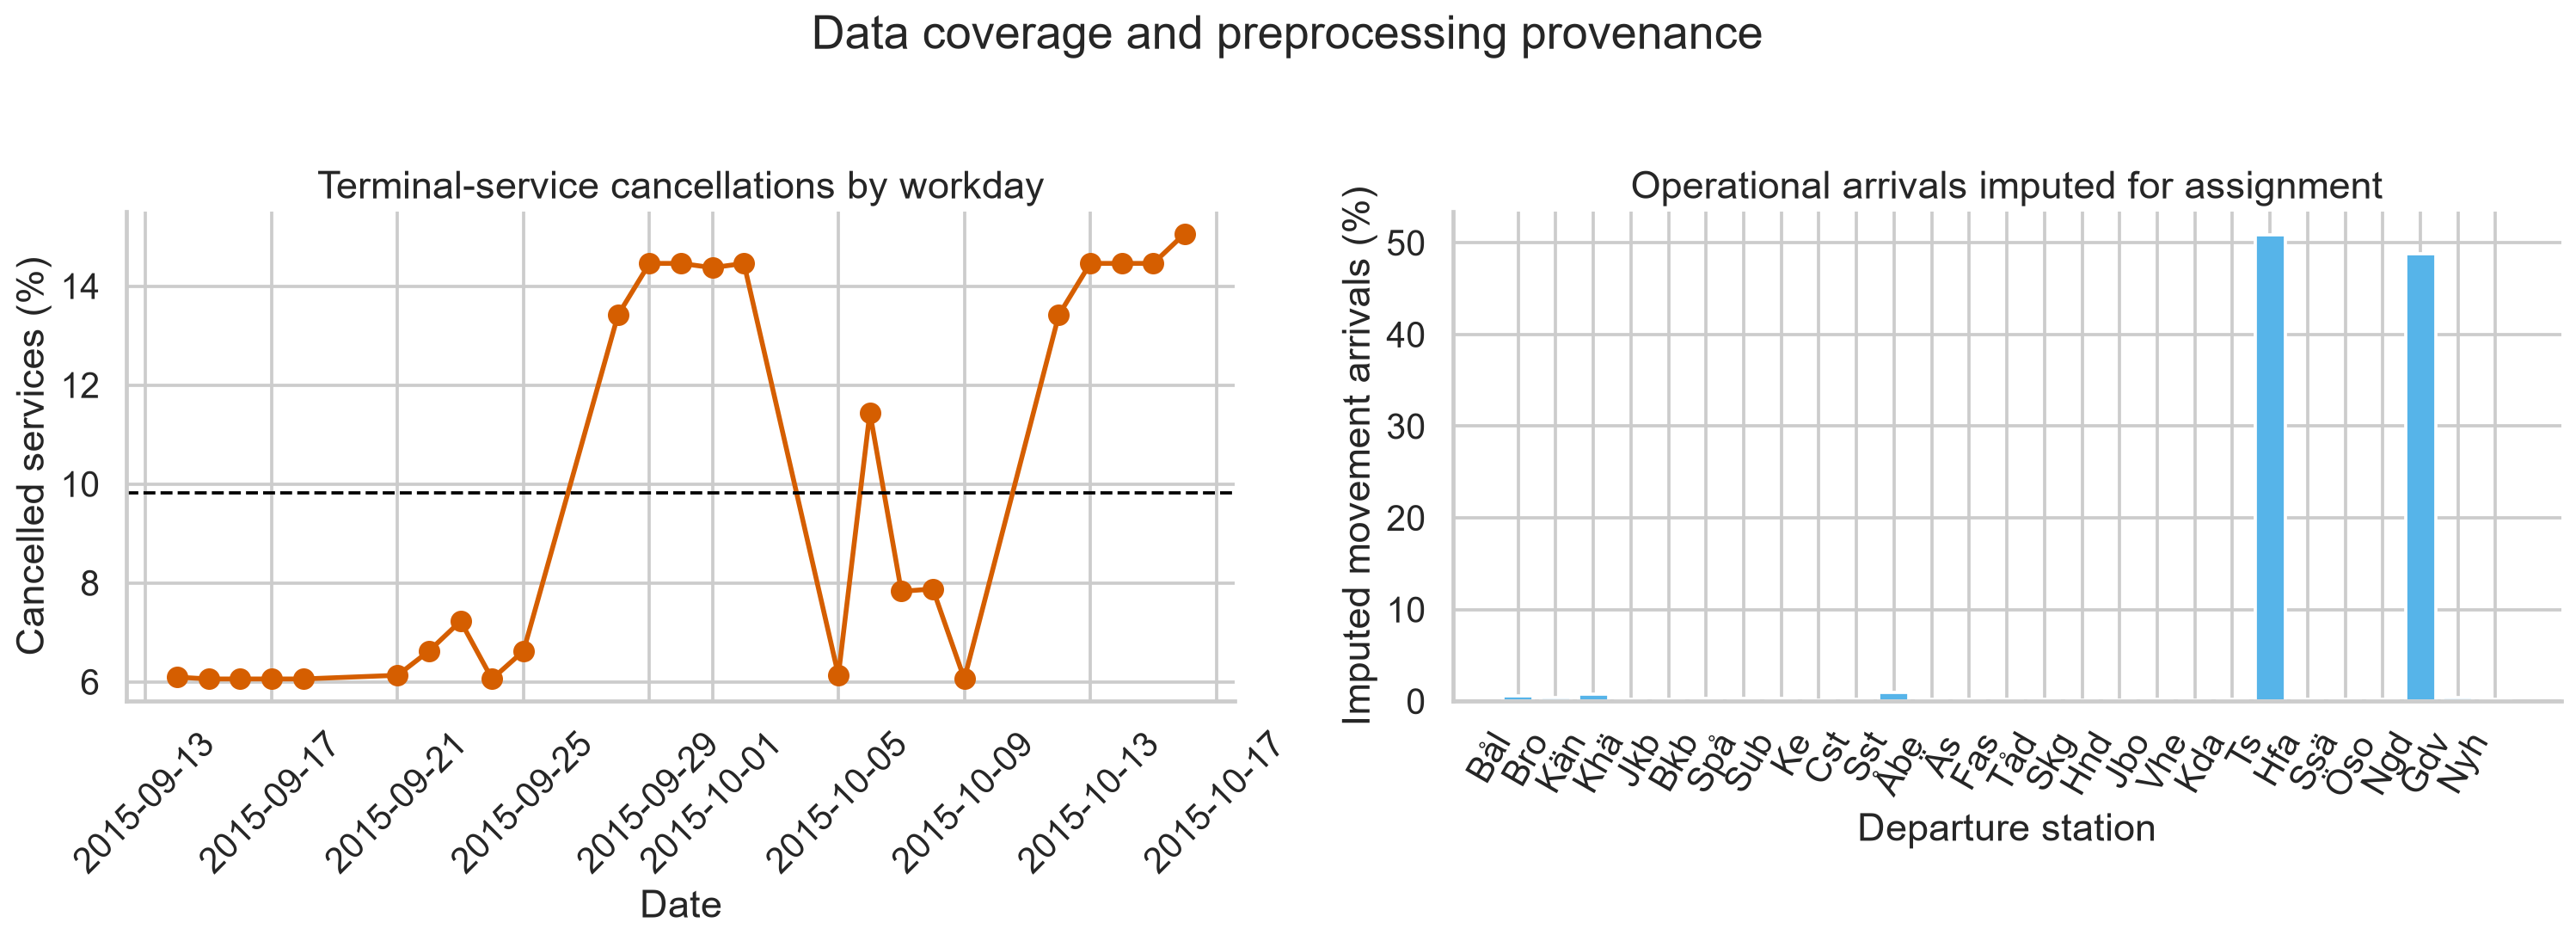

### 02 Punctuality Curves

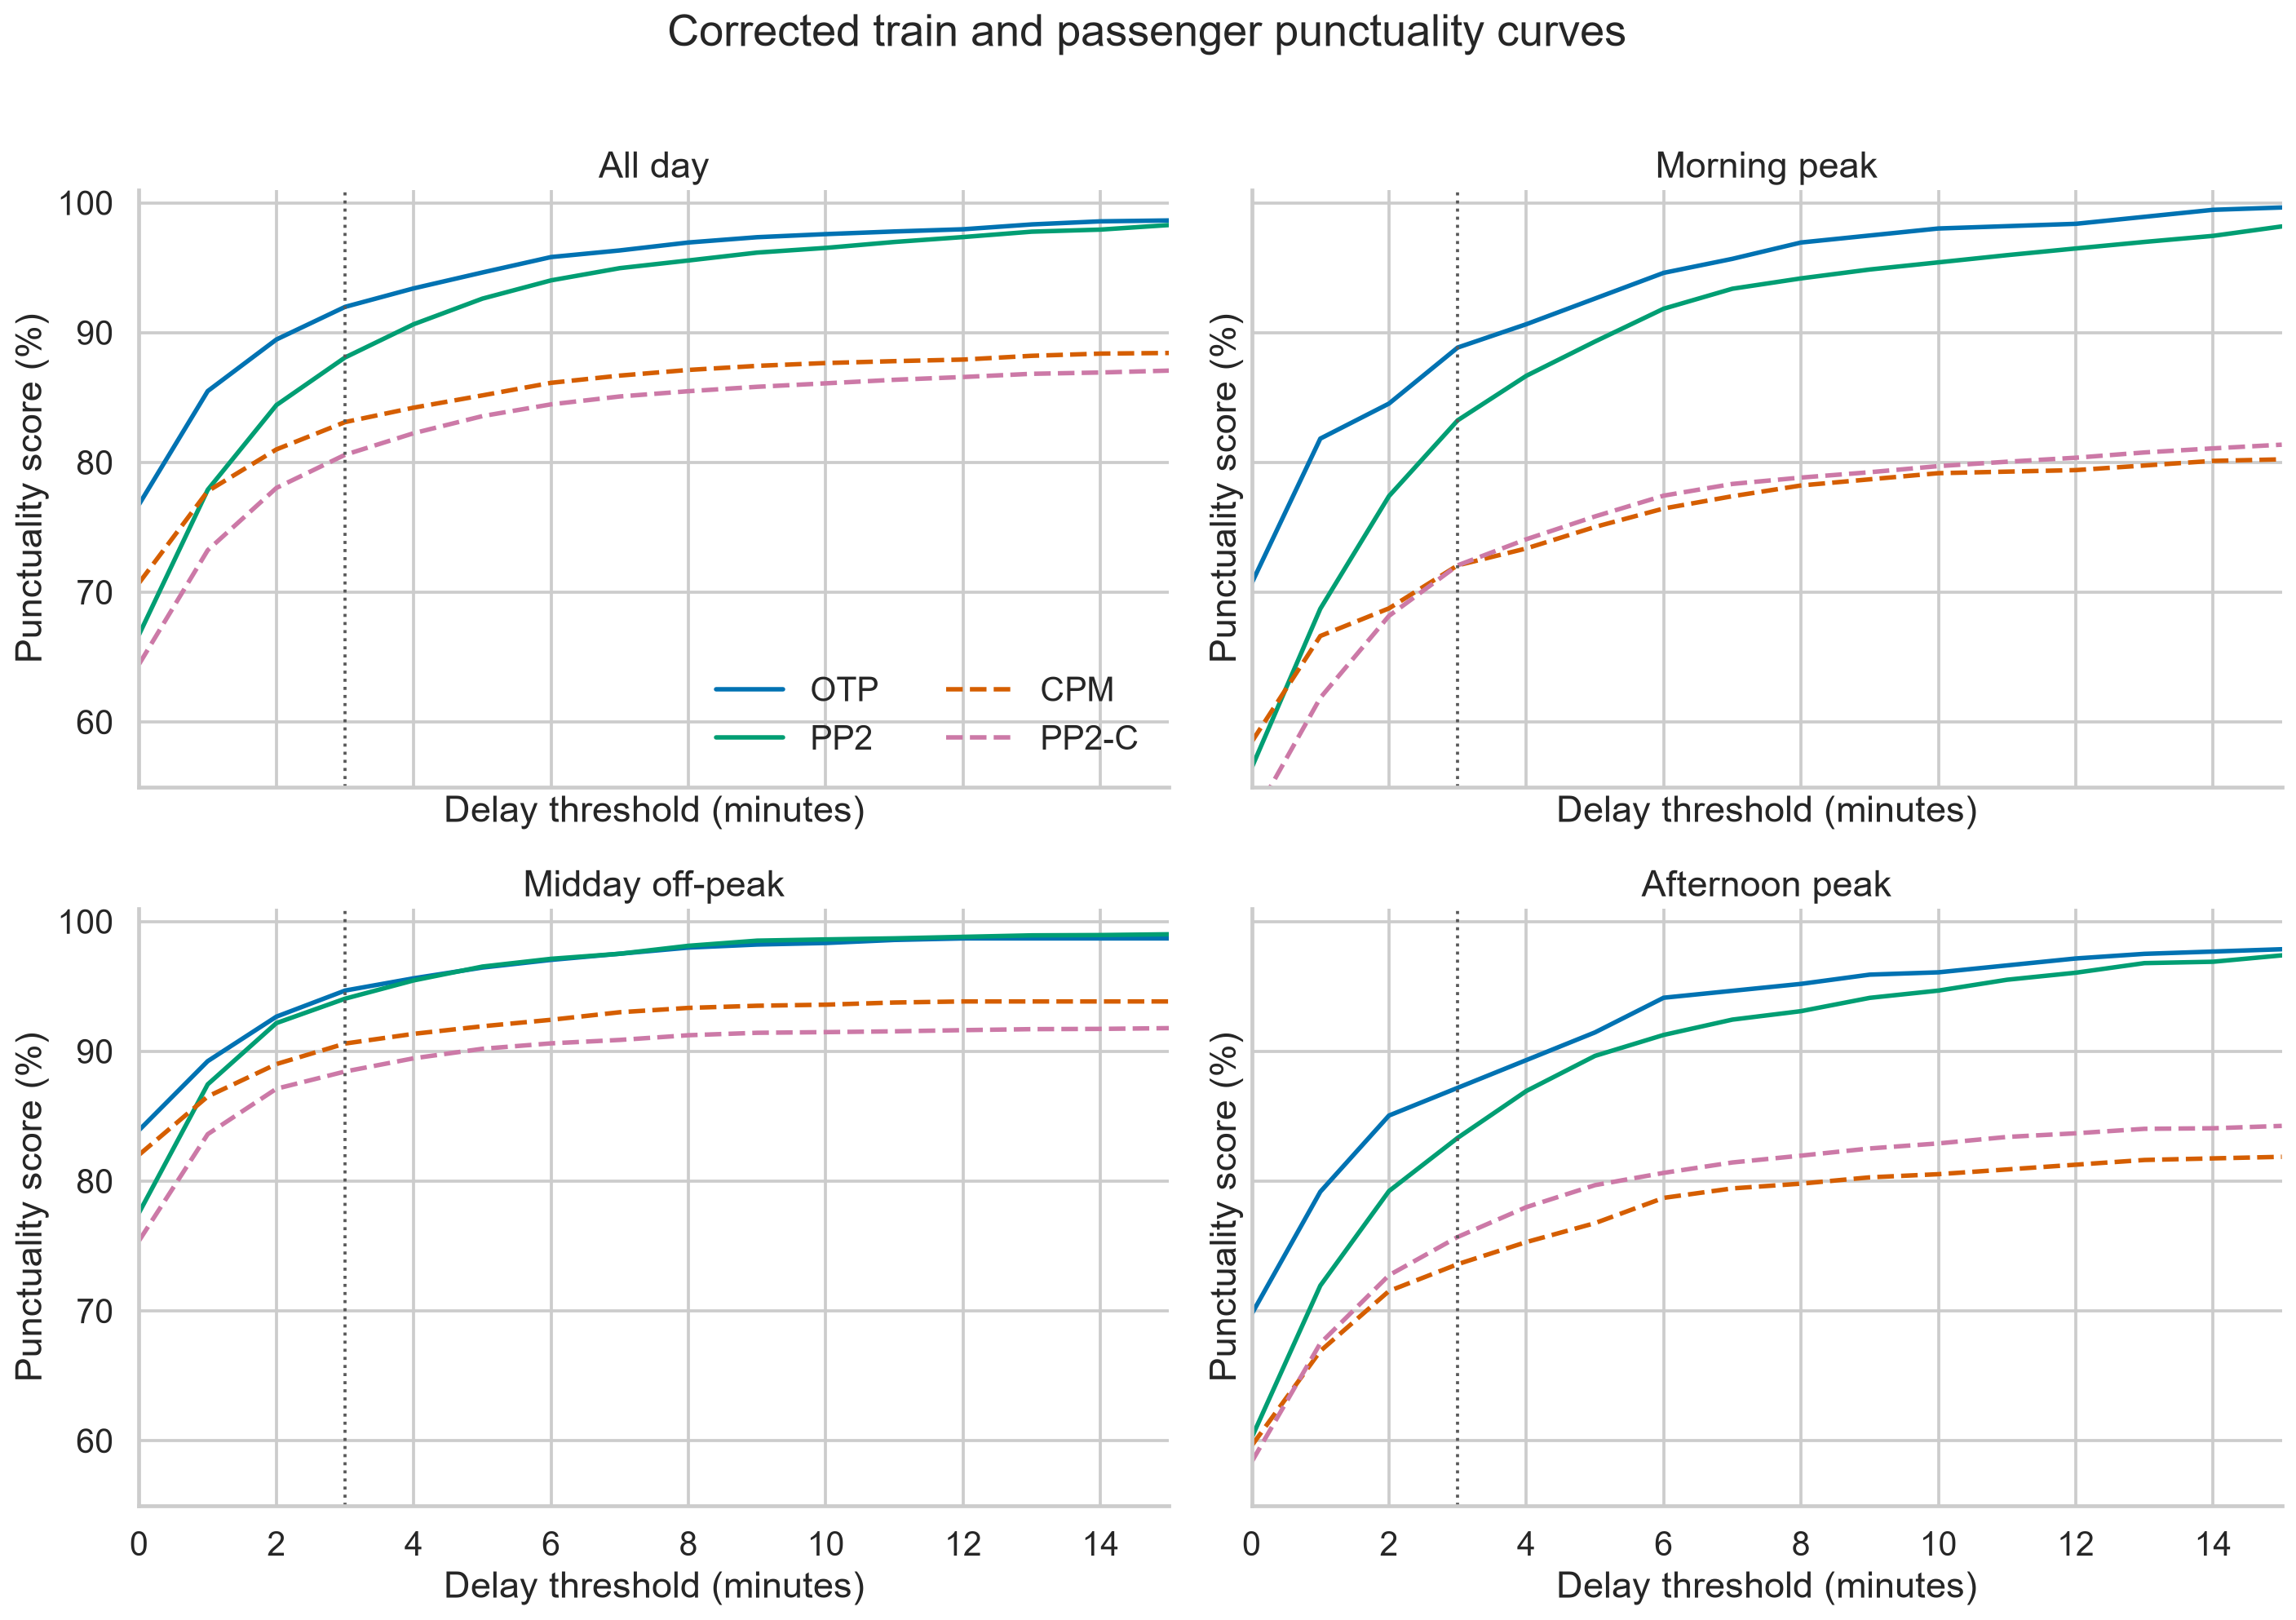

### 03 Metric Summary

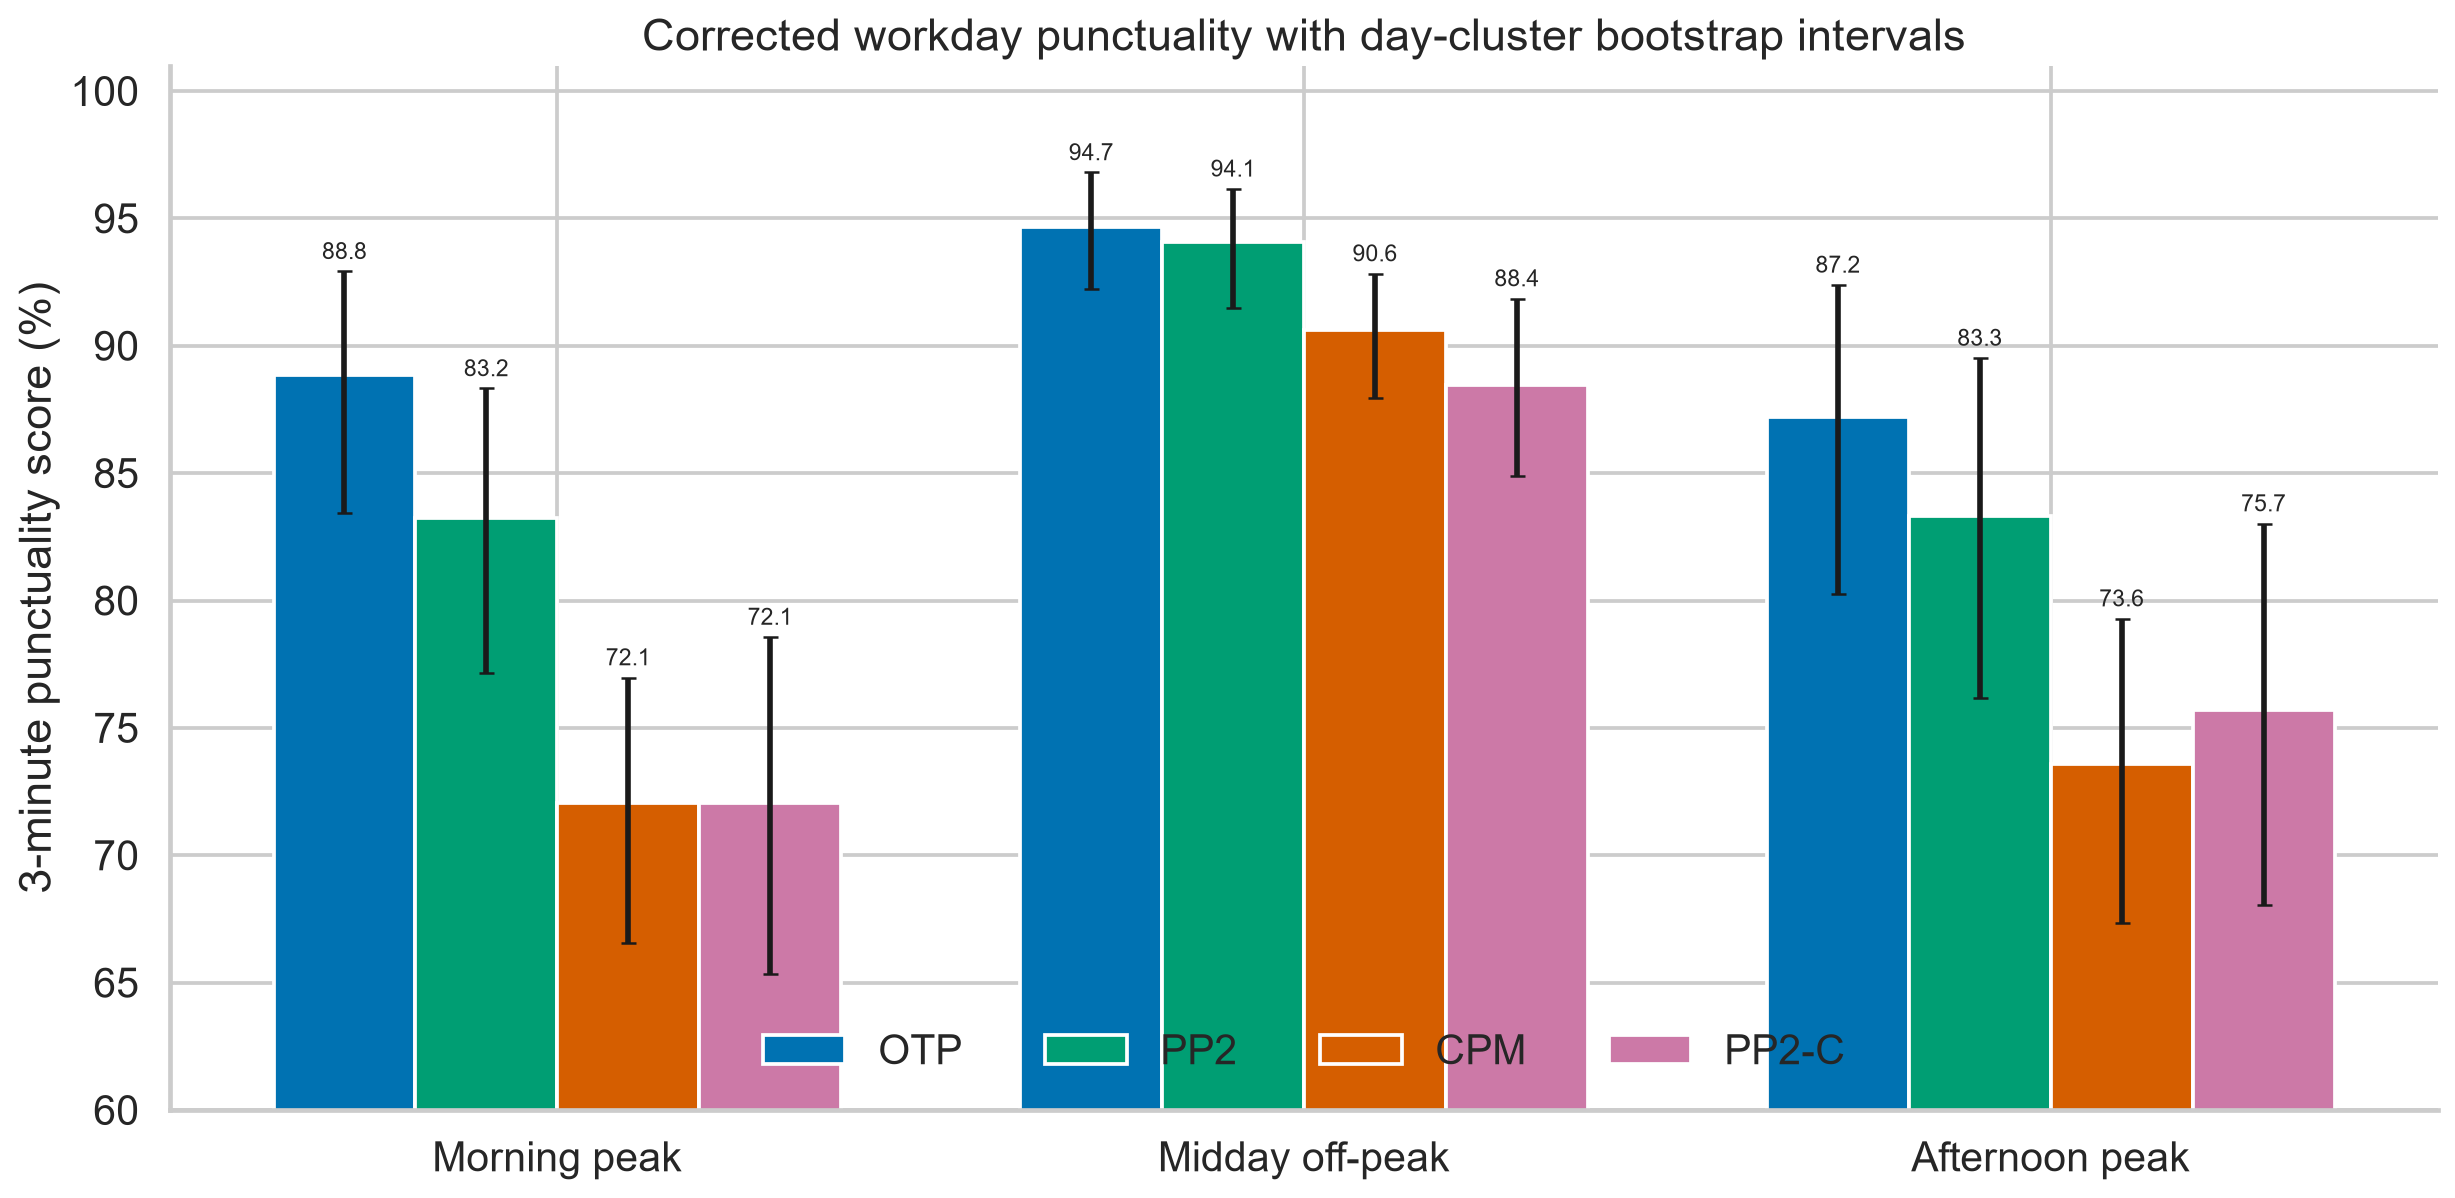

### 04 Period Sensitivity

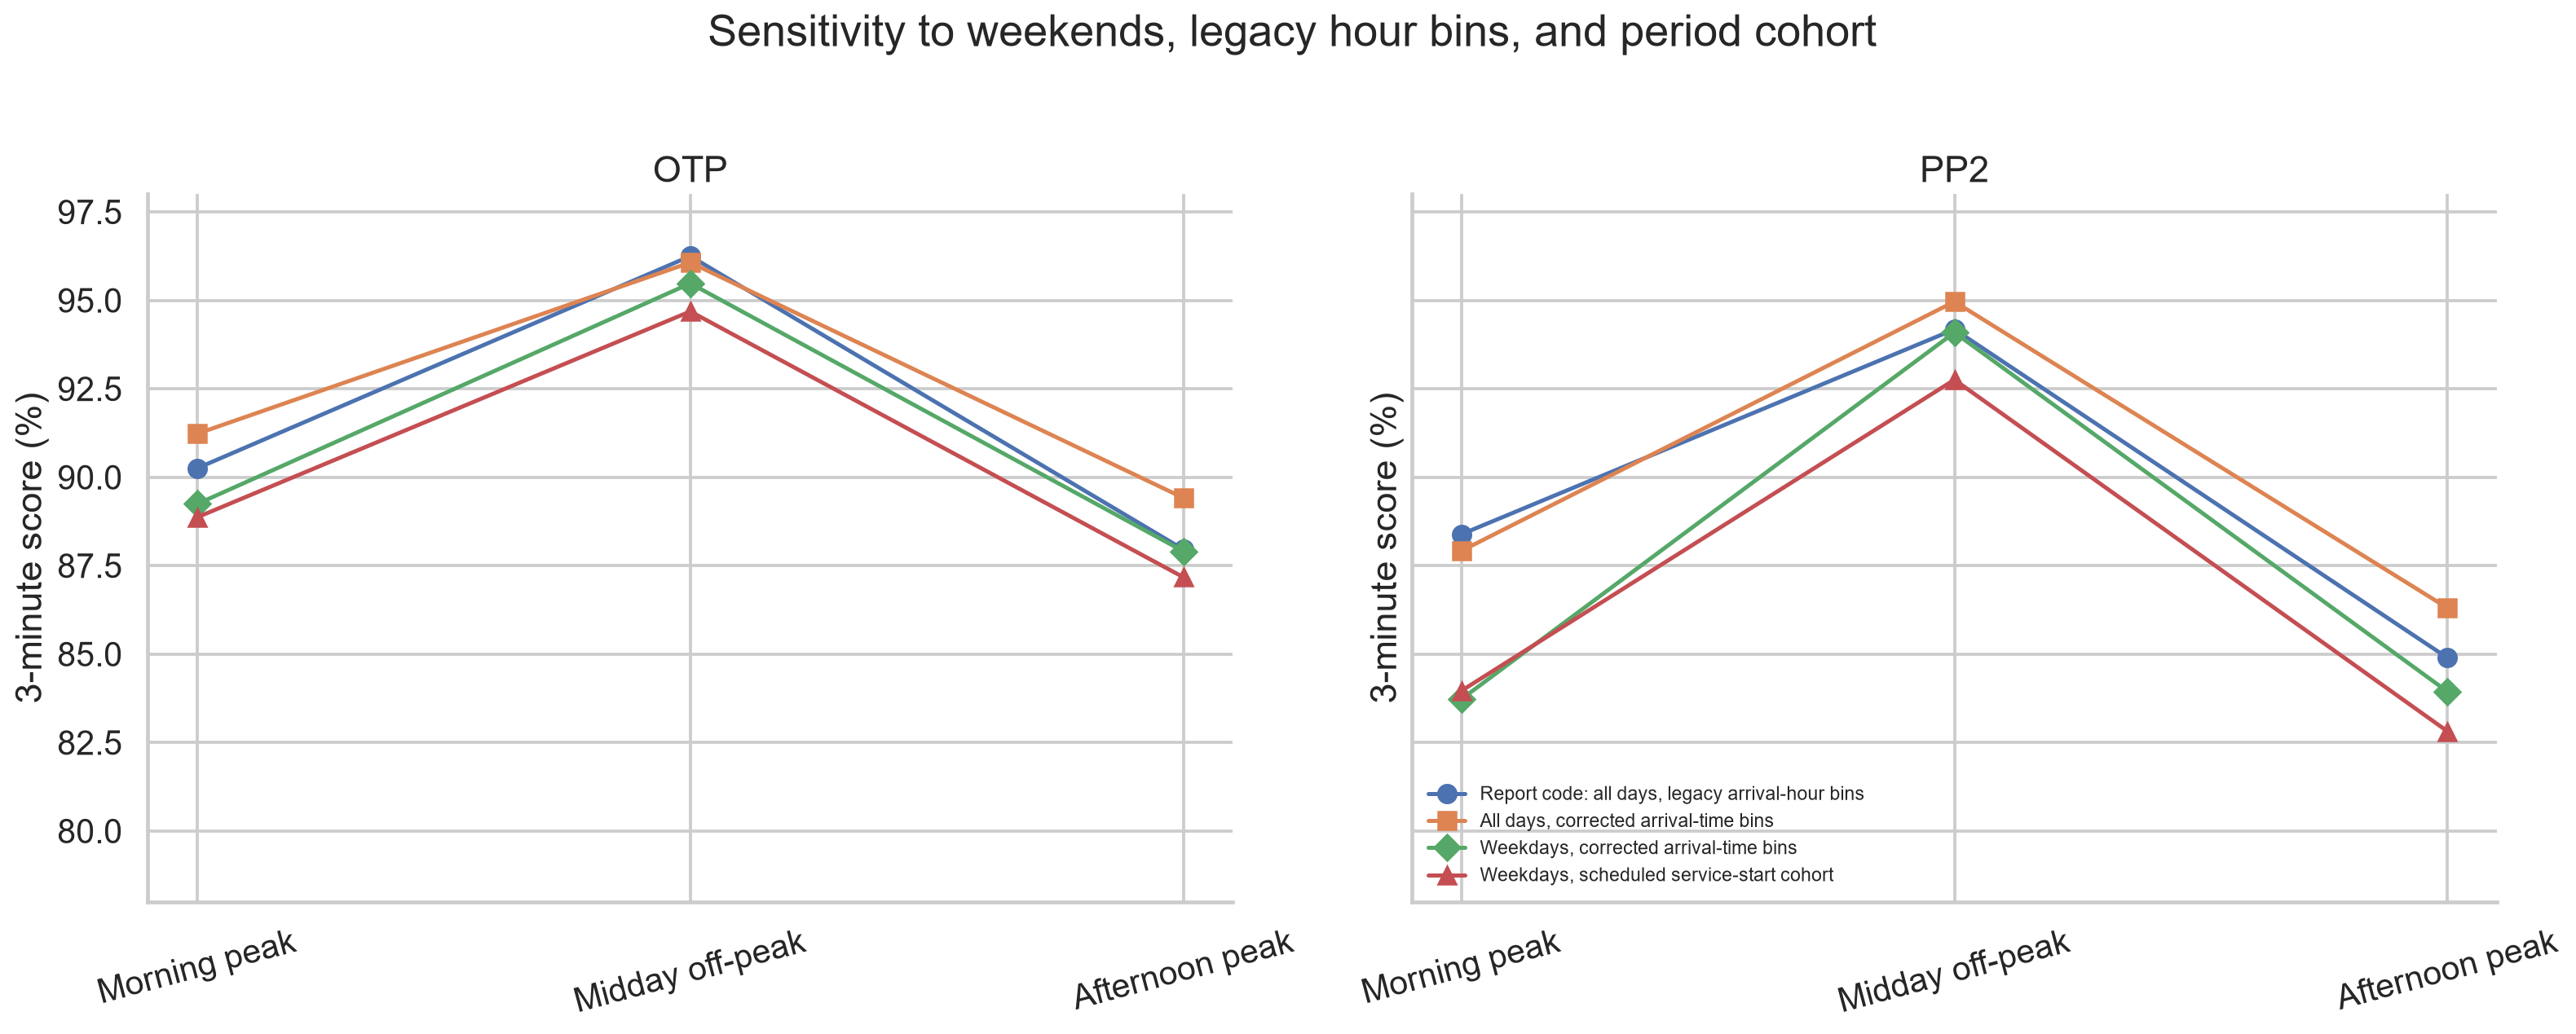

### 05 Weighted Journey Quantiles

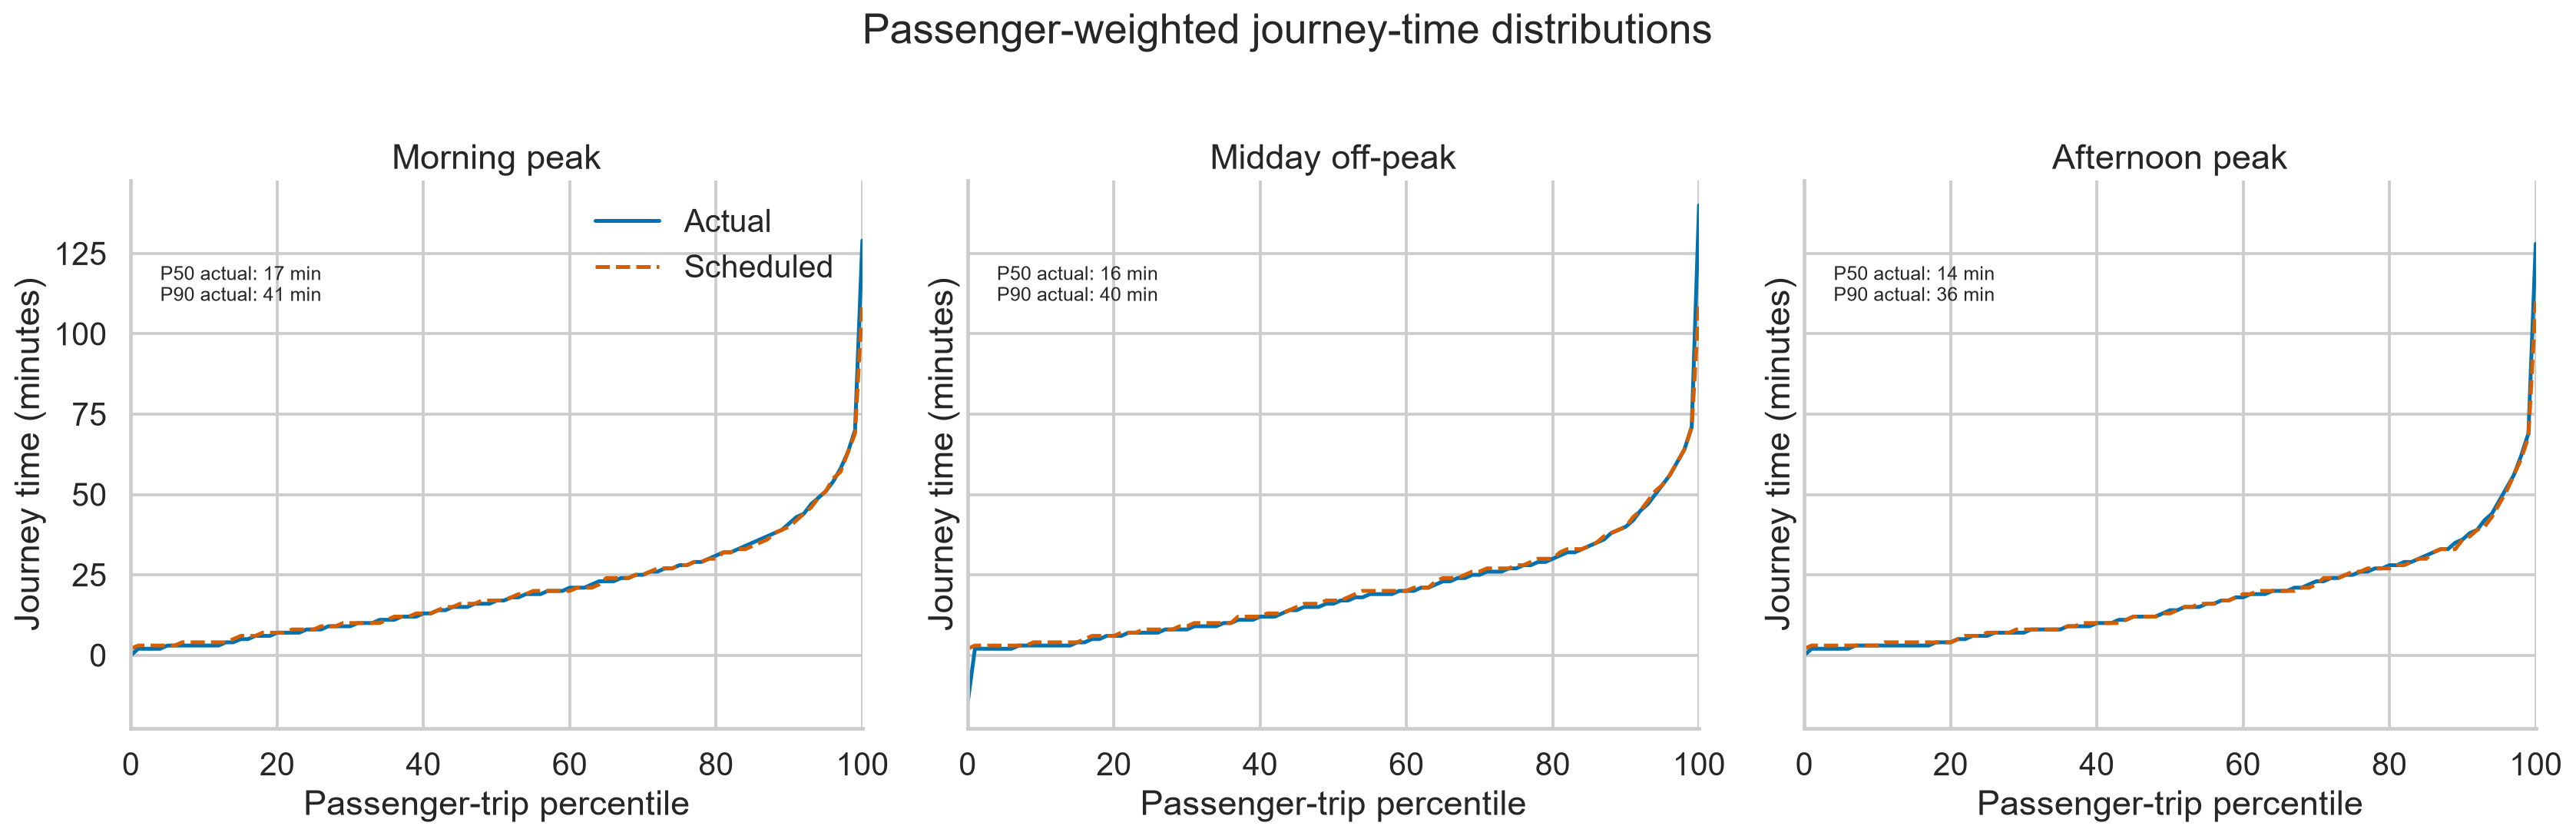

### 06 Od Reliability

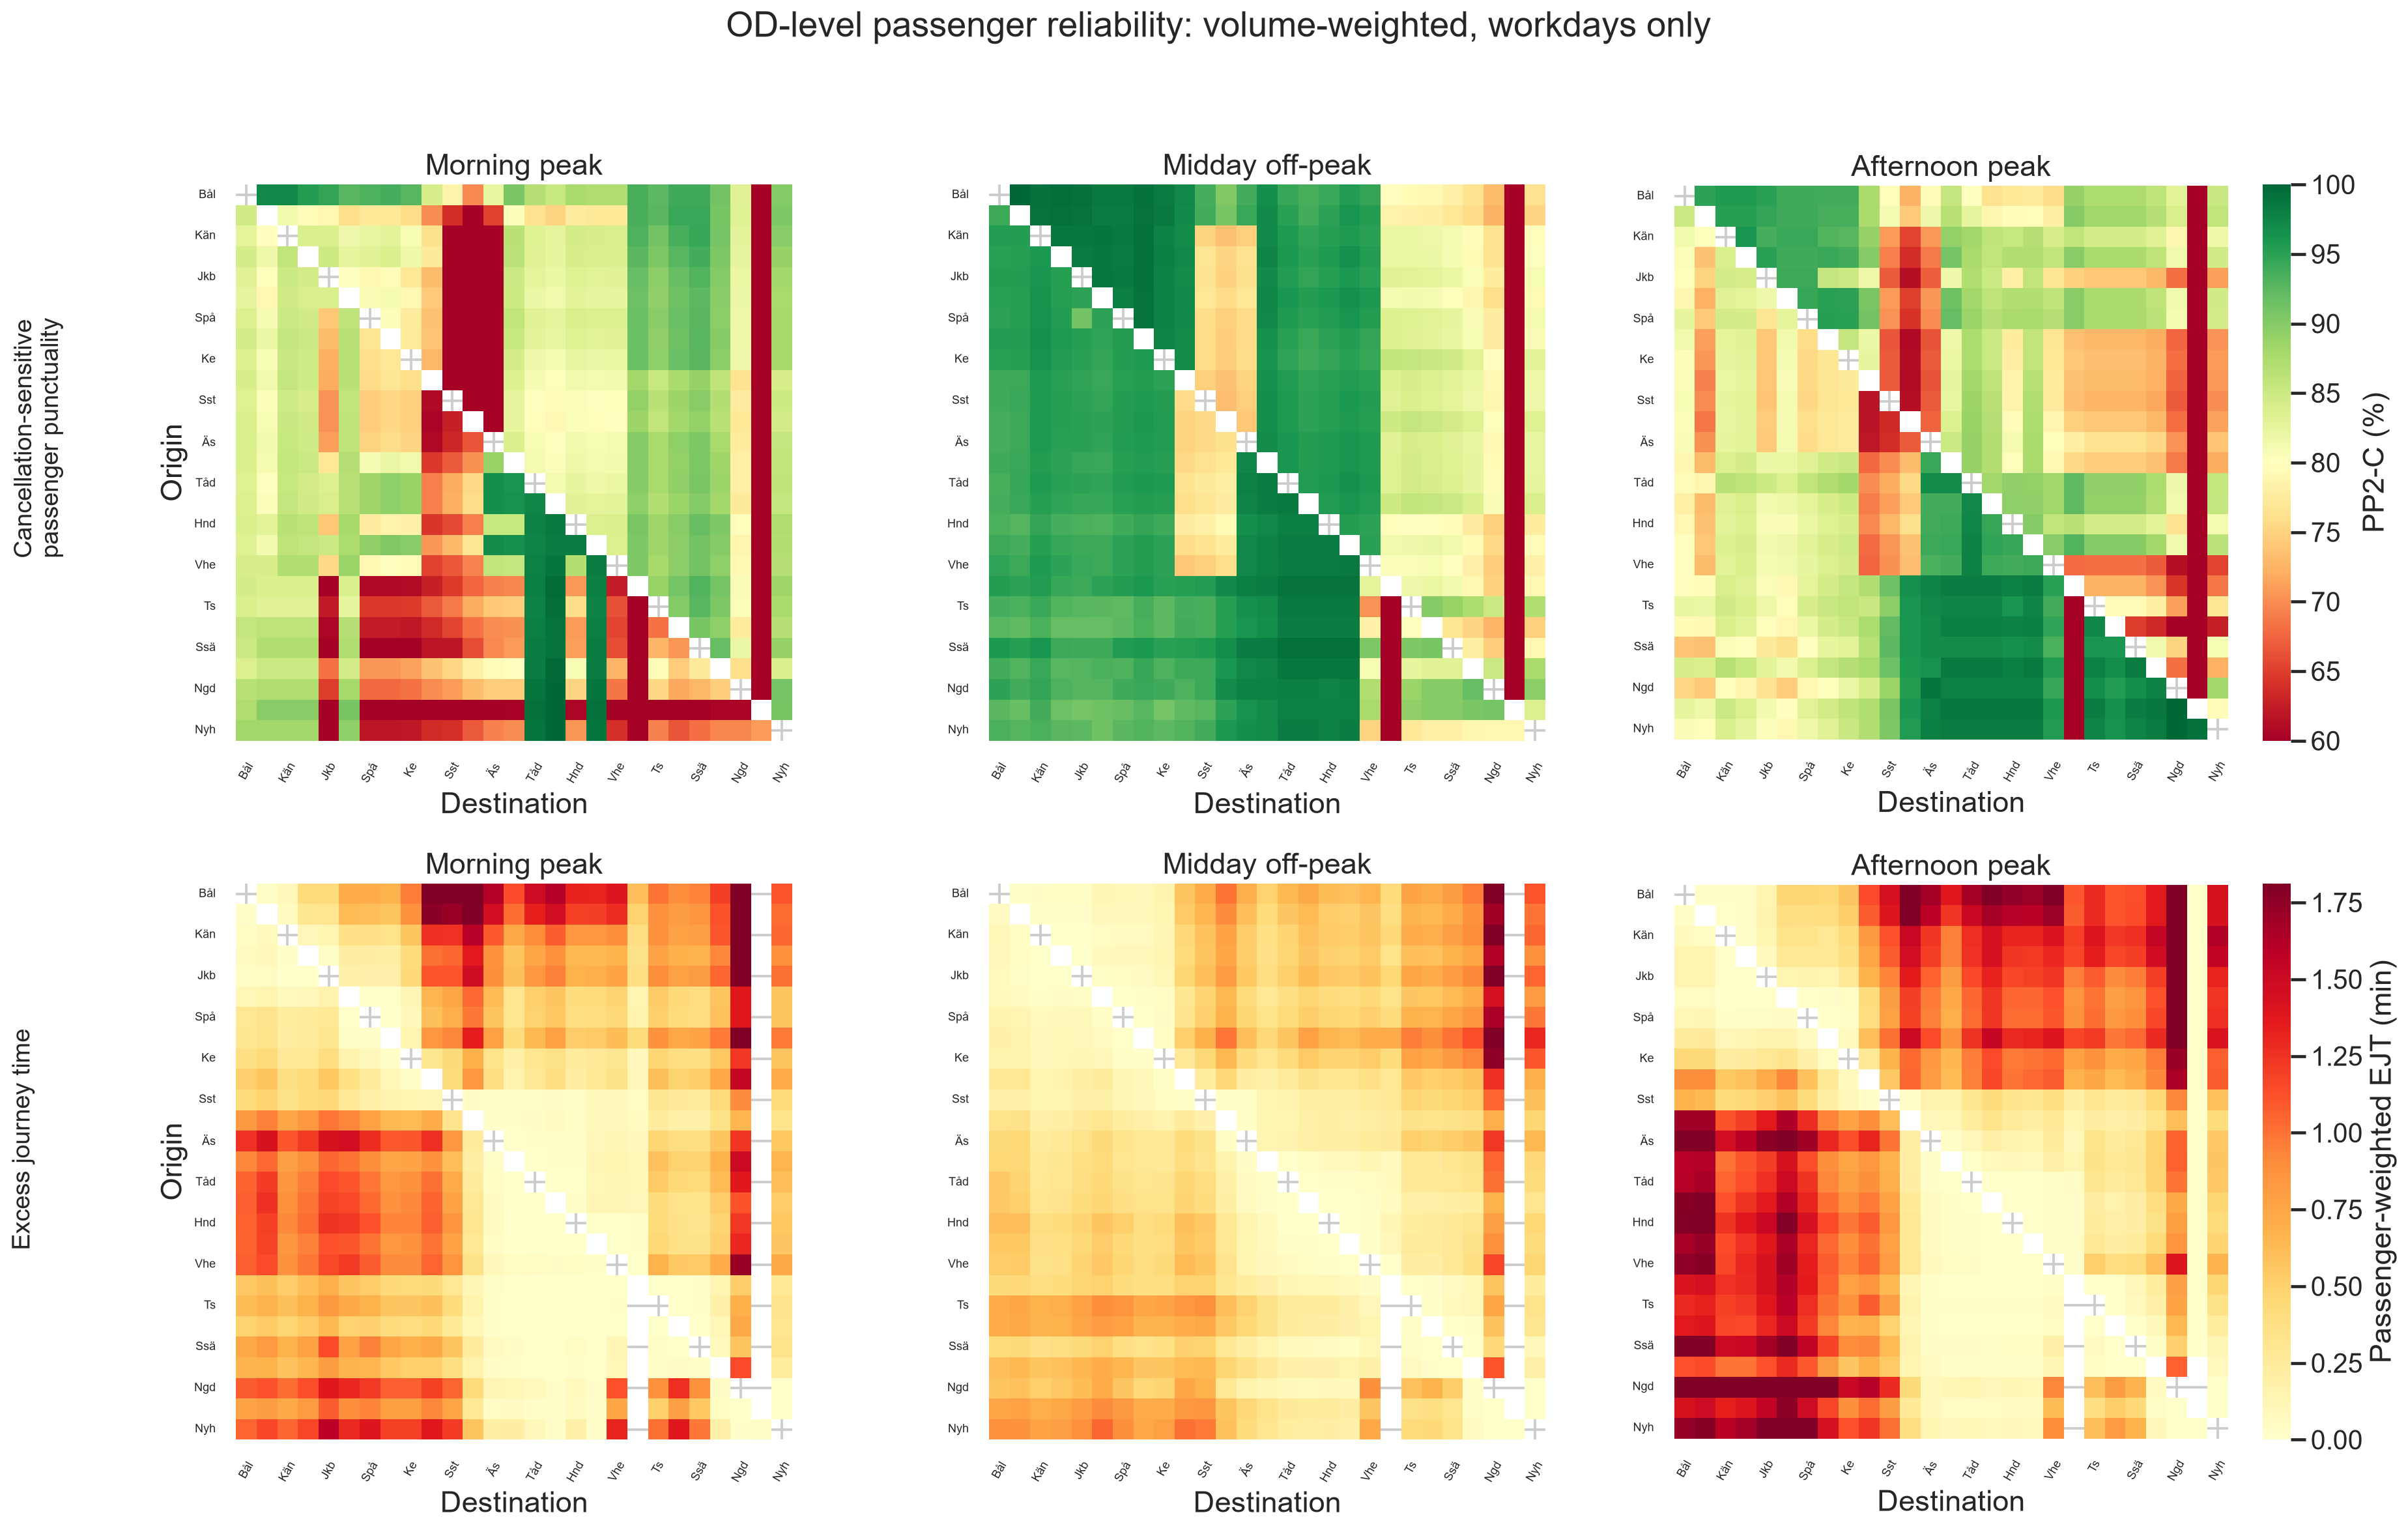

### 07 Expected Wait

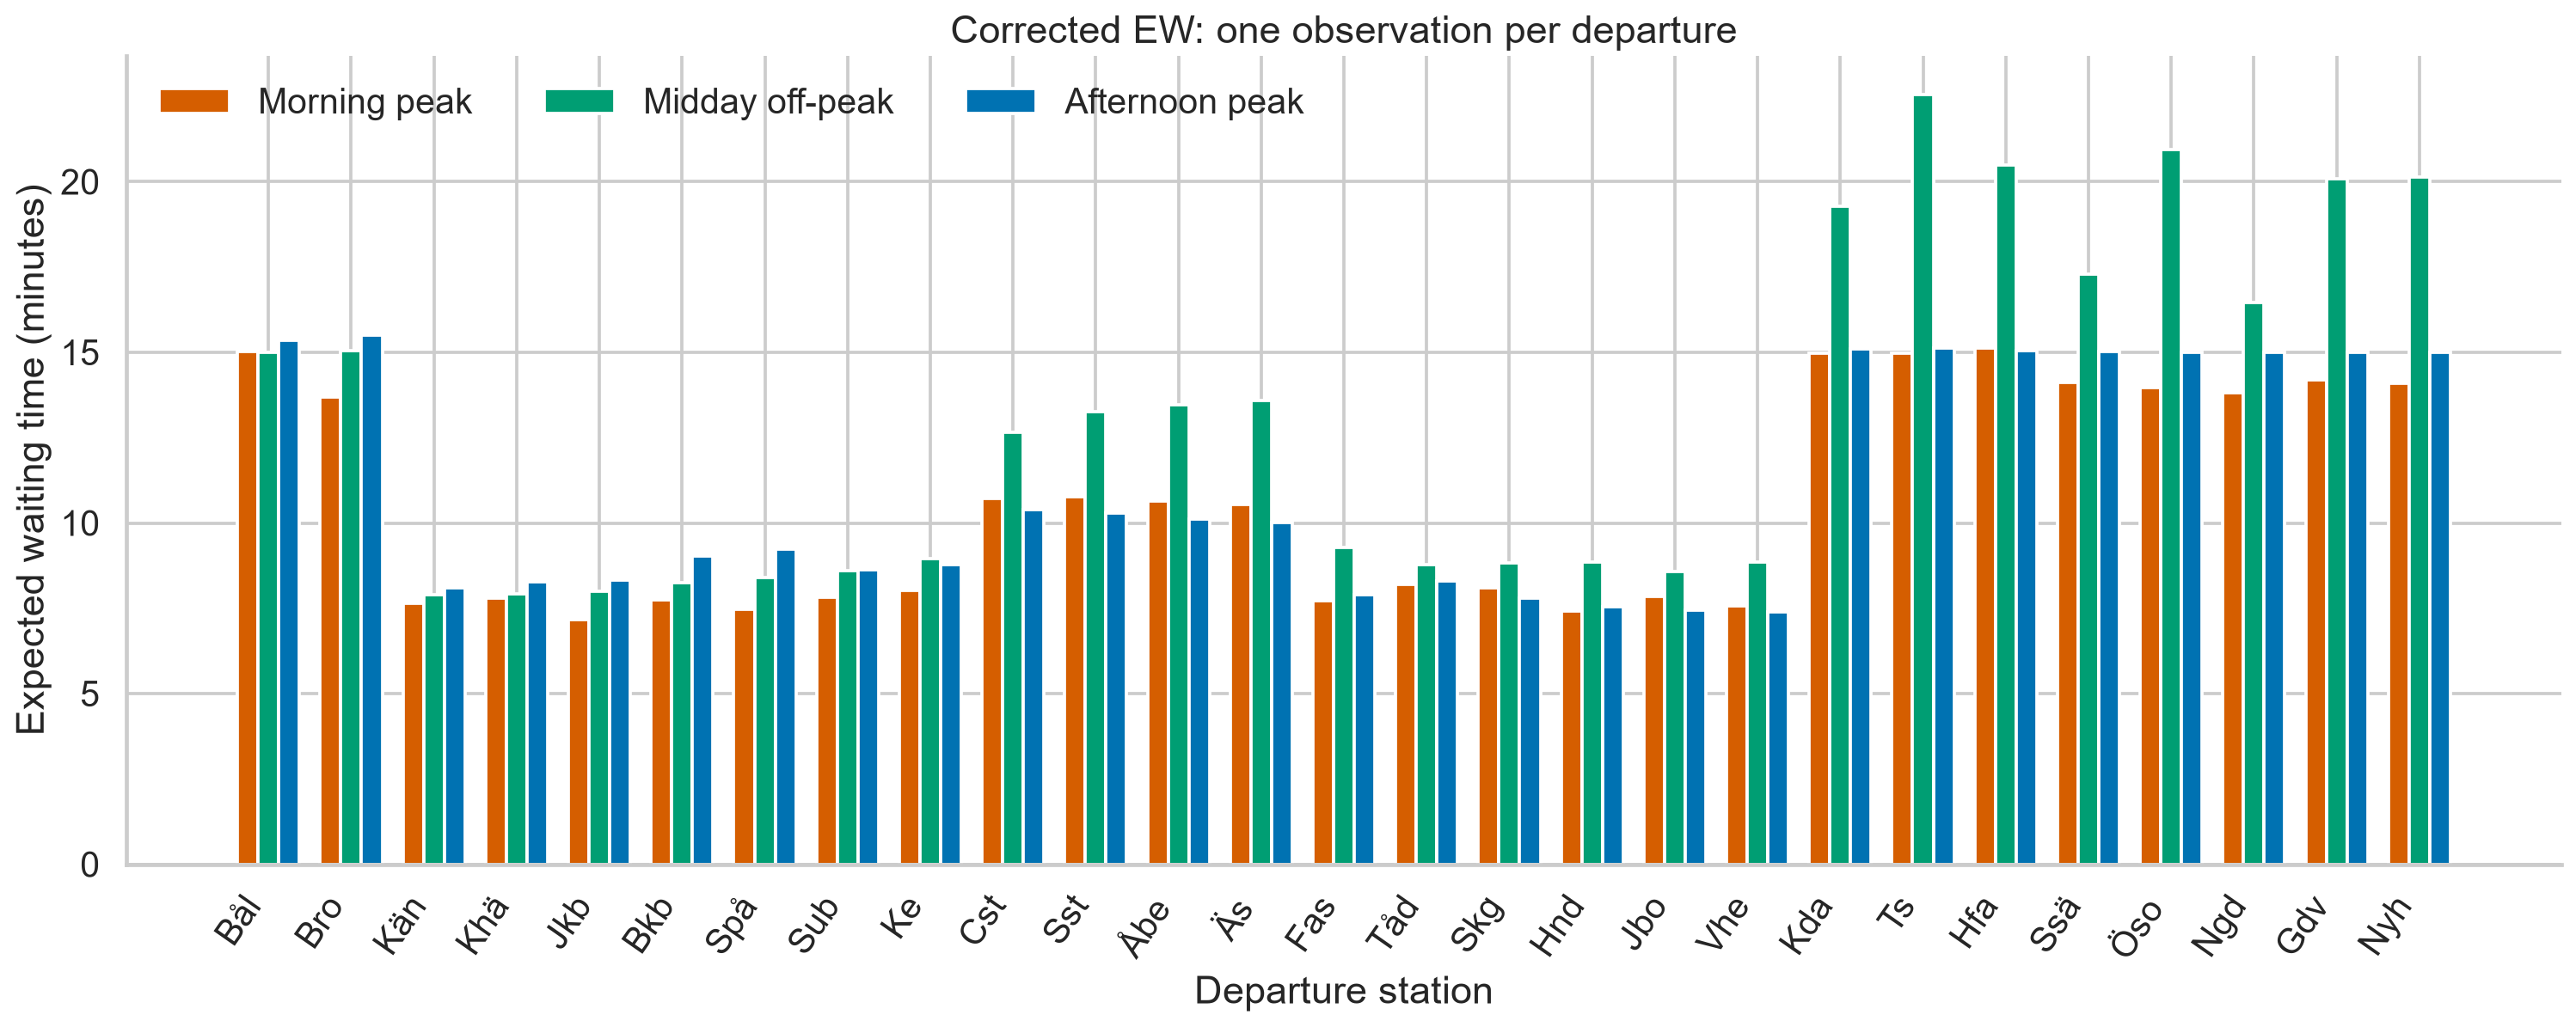

### 08 Od Risk Comparison

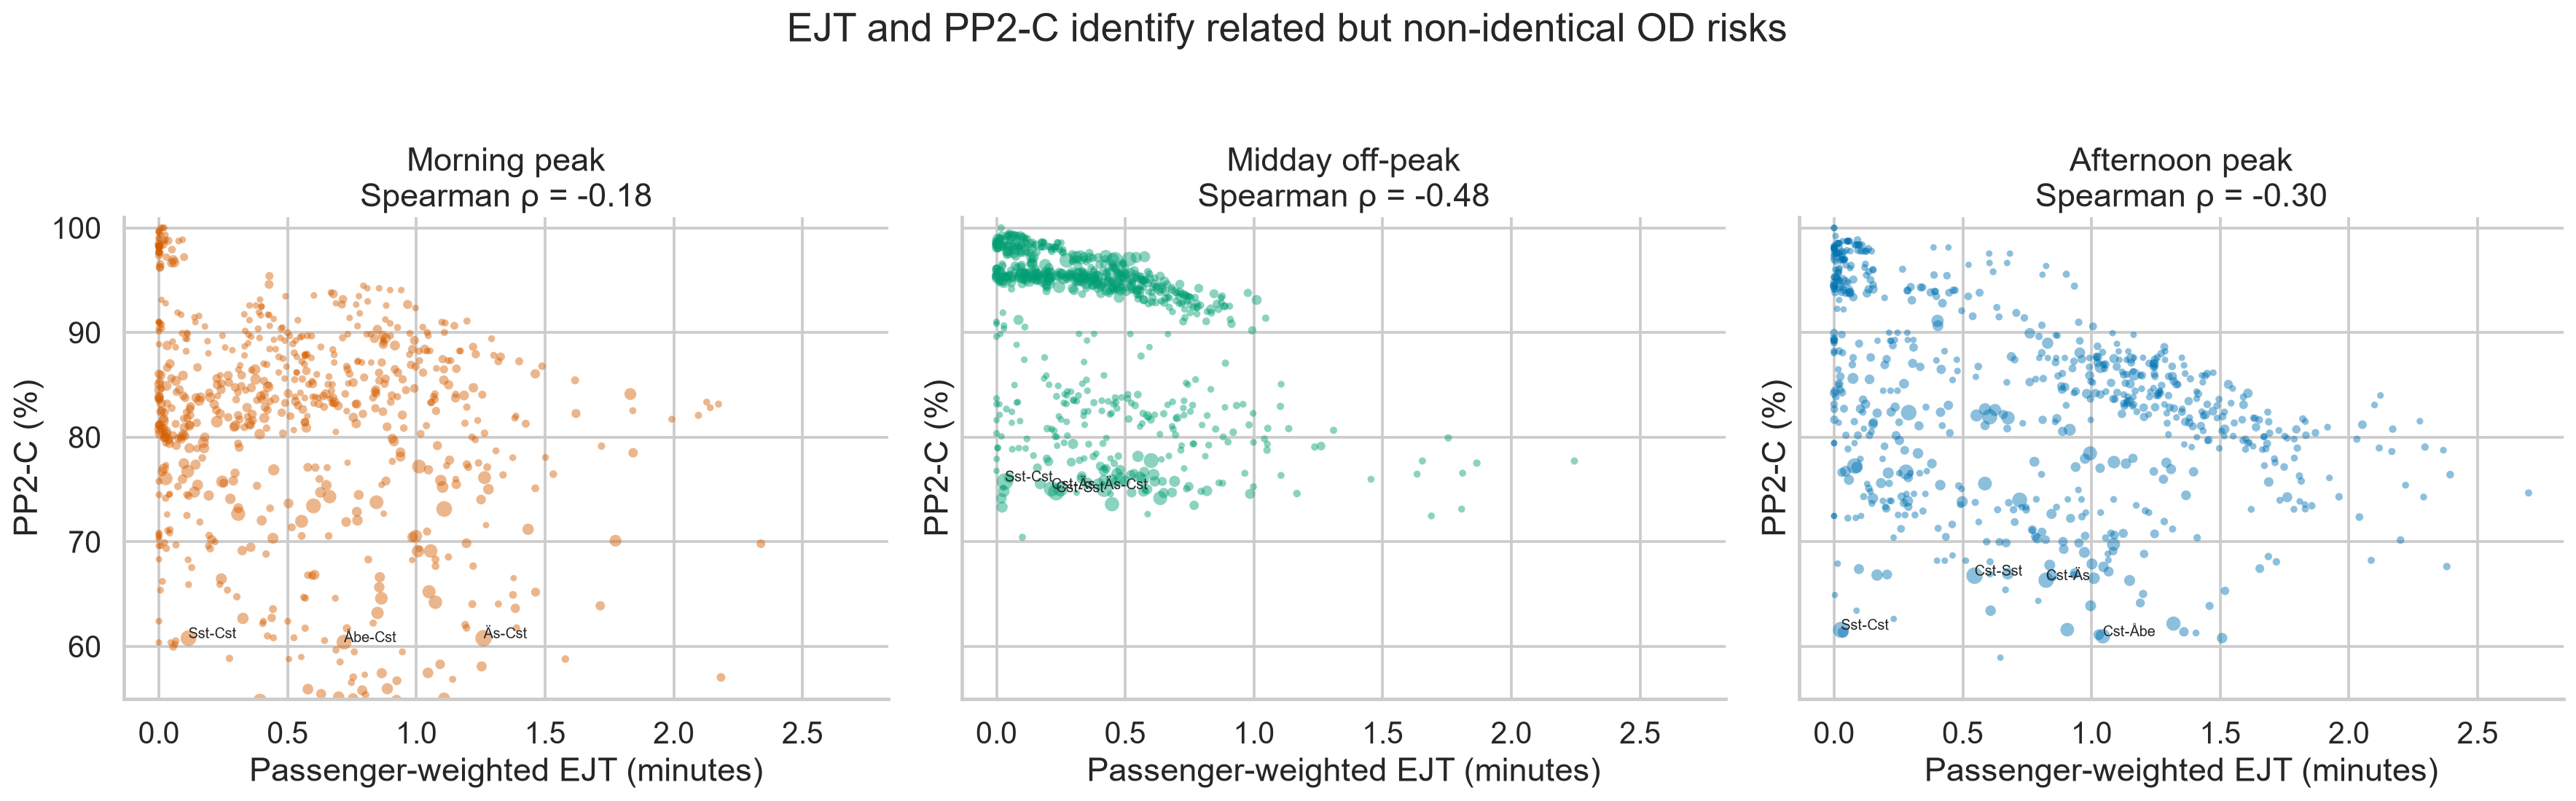

### 09 Station Ridership Weighting

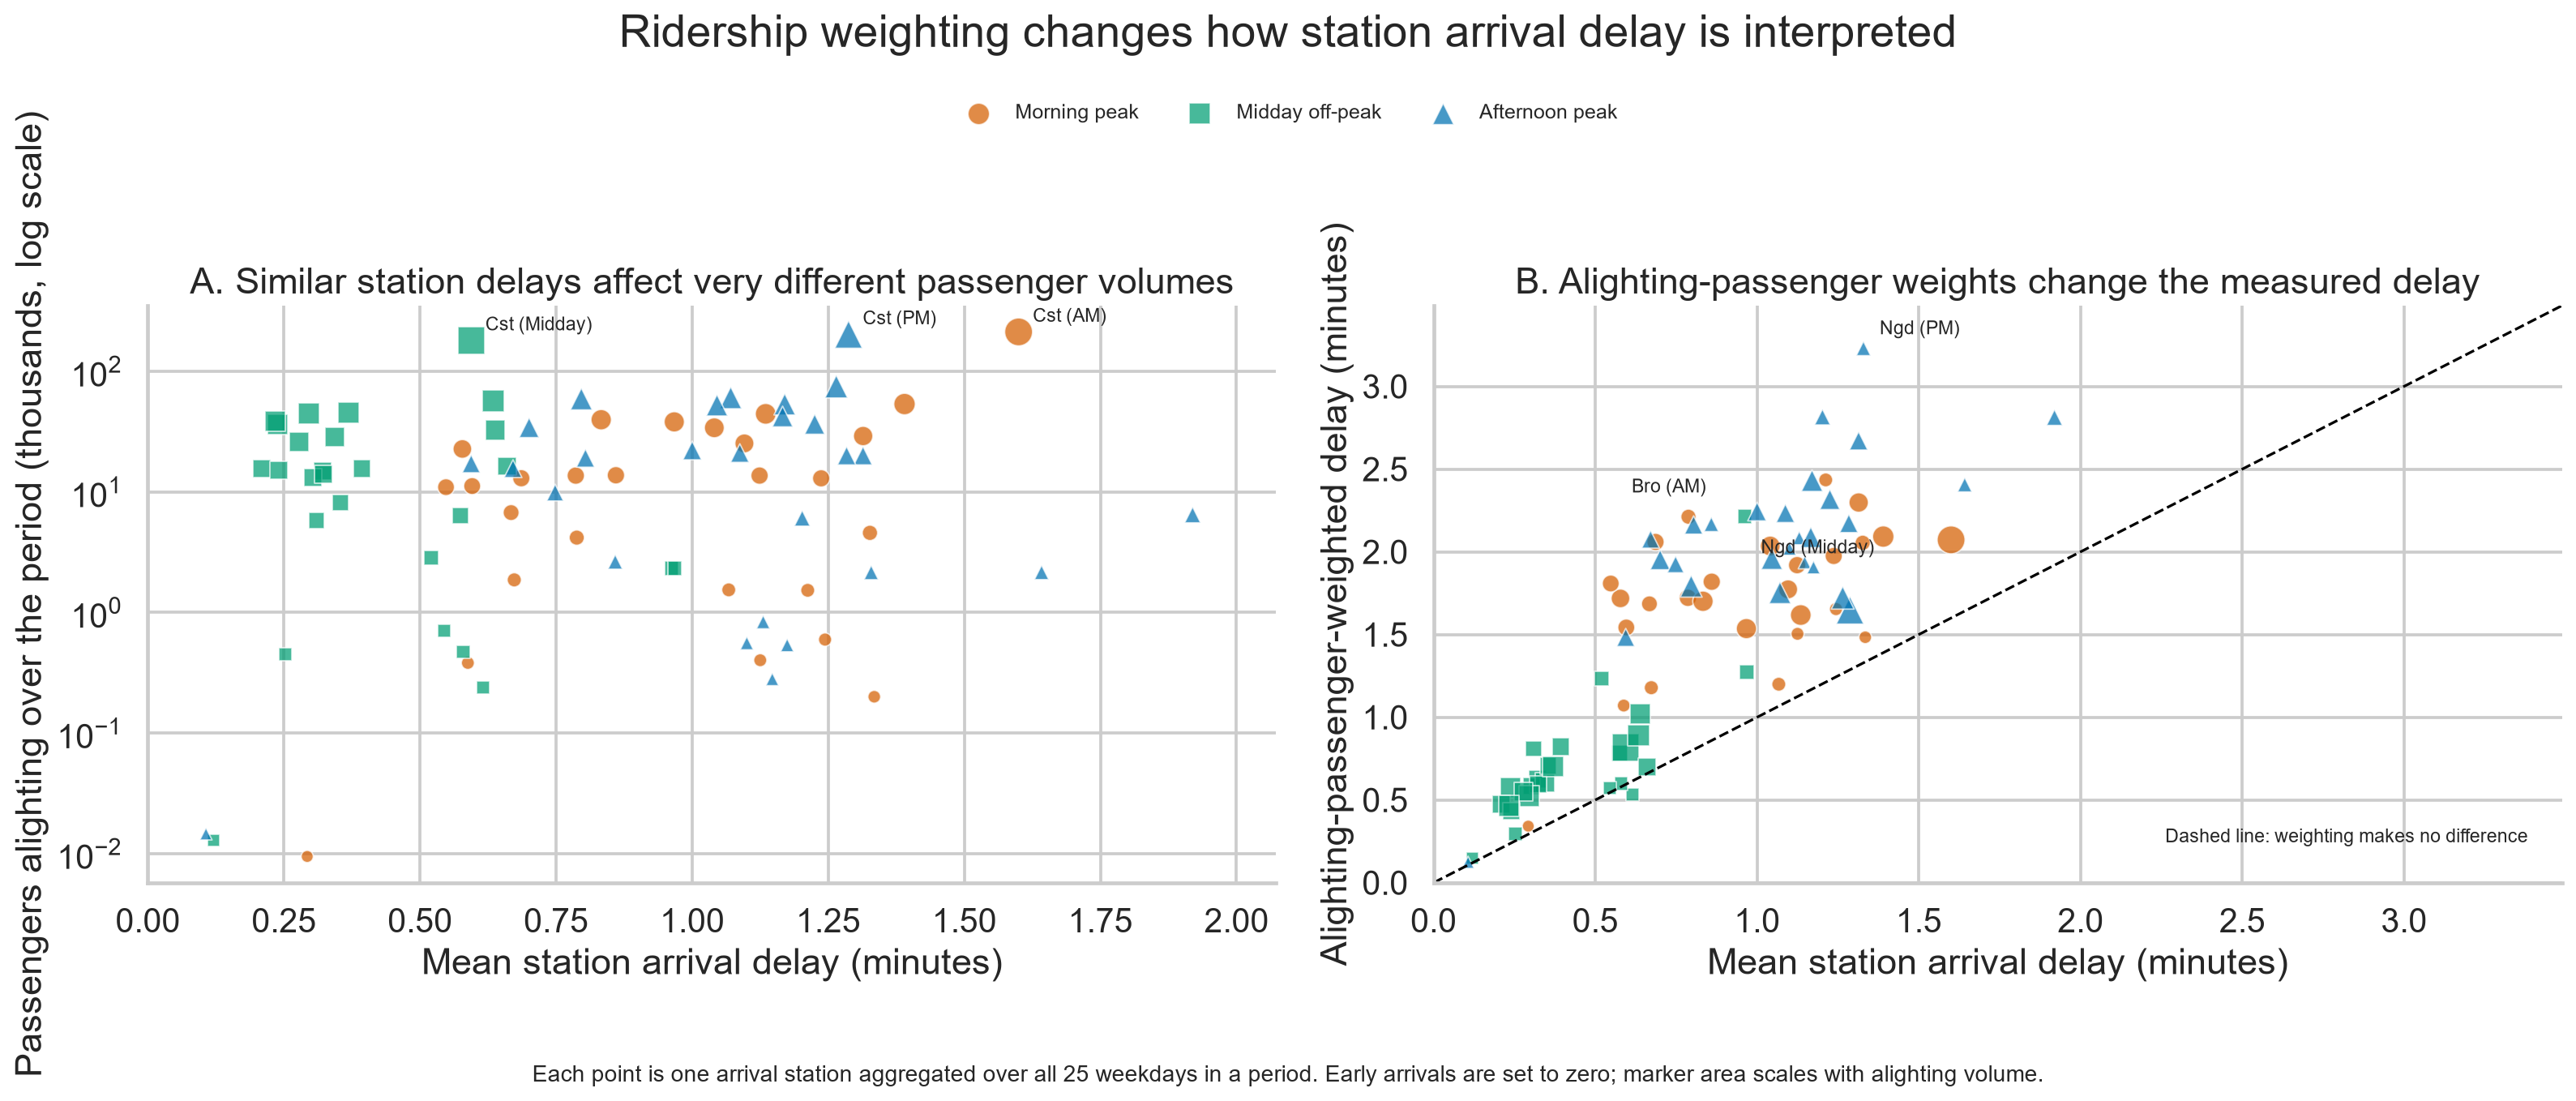

In [3]:
for figure in sorted((OUTPUT / 'figures').glob('*.png')):
    display(Markdown(f'### {figure.stem.replace("_", " ").title()}'))
    display(Image(filename=str(figure)))